In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/Datasets/Screen Time Impact on Mental Health/digital_habits_vs_mental_health.csv')

df.head()

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,mood_score
0,10.3,2,5.3,4.4,10,5
1,6.5,5,3.5,6.2,8,8
2,9.1,4,2.8,6.6,7,8
3,6.5,3,2.5,6.5,7,9
4,2.1,3,1.2,7.8,2,10


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   screen_time_hours            100000 non-null  float64
 1   social_media_platforms_used  100000 non-null  int64  
 2   hours_on_TikTok              100000 non-null  float64
 3   sleep_hours                  100000 non-null  float64
 4   stress_level                 100000 non-null  int64  
 5   mood_score                   100000 non-null  int64  
dtypes: float64(3), int64(3)
memory usage: 4.6 MB


In [ ]:
df.isnull().sum()

,0
screen_time_hours,0
social_media_platforms_used,0
hours_on_TikTok,0
sleep_hours,0
stress_level,0
mood_score,0


In [ ]:
df['stress_level'].value_counts()

,count
stress_level,
6,18516
7,17274
5,16119
8,13041
4,11381
9,7719
3,6207
10,6119
2,2592


In [ ]:
stress_free=df[df['stress_level']==1]
stress_free.head()

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,mood_score
143,6.9,5,2.1,10.0,1,10
362,2.2,2,0.7,9.3,1,10
392,1.9,3,0.9,8.8,1,10
436,1.9,5,0.6,9.6,1,10
583,1.4,5,0.5,9.4,1,10


In [ ]:
df=df.drop(["mood_score"],axis=1)

In [ ]:
df['non_tiktok_screen_time']=df['screen_time_hours'] - df['hours_on_TikTok']
df.head()

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,non_tiktok_screen_time
0,10.3,2,5.3,4.4,10,5.0
1,6.5,5,3.5,6.2,8,3.0
2,9.1,4,2.8,6.6,7,6.3
3,6.5,3,2.5,6.5,7,4.0
4,2.1,3,1.2,7.8,2,0.9


In [ ]:
df['screen_time_to_sleep_ratio']=df['screen_time_hours']/df['sleep_hours']
df.head()

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,non_tiktok_screen_time,screen_time_to_sleep_ratio
0,10.3,2,5.3,4.4,10,5.0,2.340909
1,6.5,5,3.5,6.2,8,3.0,1.048387
2,9.1,4,2.8,6.6,7,6.3,1.378788
3,6.5,3,2.5,6.5,7,4.0,1.000000
4,2.1,3,1.2,7.8,2,0.9,0.269231


https://psycnet.apa.org/doiLanding?doi=10.1037%2Ft05183-000

Need to apply the scale:

Score,Category,Typical Experience
1–3,Low,Alert but calm; no physical tension.
4–6,Moderate,"Functional but ""on edge""; physical tension starts."
7–8,High,Distracted by anxiety; physical signs like racing heart.
9–10,Severe,"Peak distress; feeling ""frozen"" or in a crisis."

In [ ]:


conditions = [
    (df['stress_level'] >=1) & (df['stress_level'] <= 6),
    (df['stress_level'] > 6) & (df['stress_level'] <= 10),
]
choices = ['Low', 'High']
df['stress_level'] = np.select(conditions, choices, default='Unknown')
df.head()

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,non_tiktok_screen_time,screen_time_to_sleep_ratio
0,10.3,2,5.3,4.4,High,5.0,2.340909
1,6.5,5,3.5,6.2,High,3.0,1.048387
2,9.1,4,2.8,6.6,High,6.3,1.378788
3,6.5,3,2.5,6.5,High,4.0,1.000000
4,2.1,3,1.2,7.8,Low,0.9,0.269231


In [ ]:
df['stress_level'].value_counts()

,count
stress_level,
Low,55847
High,44153


In [ ]:
df['stress_level']=df['stress_level'].map({'Low':0,'High':1})
df.head()

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,non_tiktok_screen_time,screen_time_to_sleep_ratio
0,10.3,2,5.3,4.4,1,5.0,2.340909
1,6.5,5,3.5,6.2,1,3.0,1.048387
2,9.1,4,2.8,6.6,1,6.3,1.378788
3,6.5,3,2.5,6.5,1,4.0,1.000000
4,2.1,3,1.2,7.8,0,0.9,0.269231


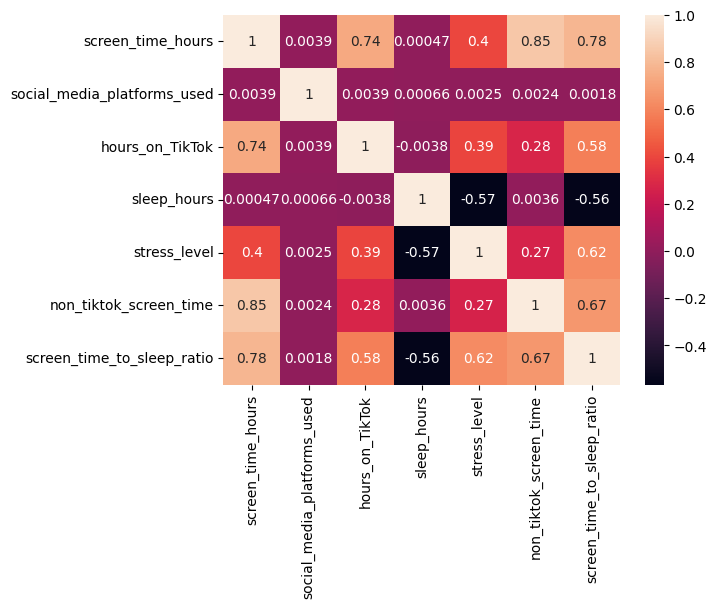

In [ ]:
correlation_matrix=sns.heatmap(df.corr(),annot=True)

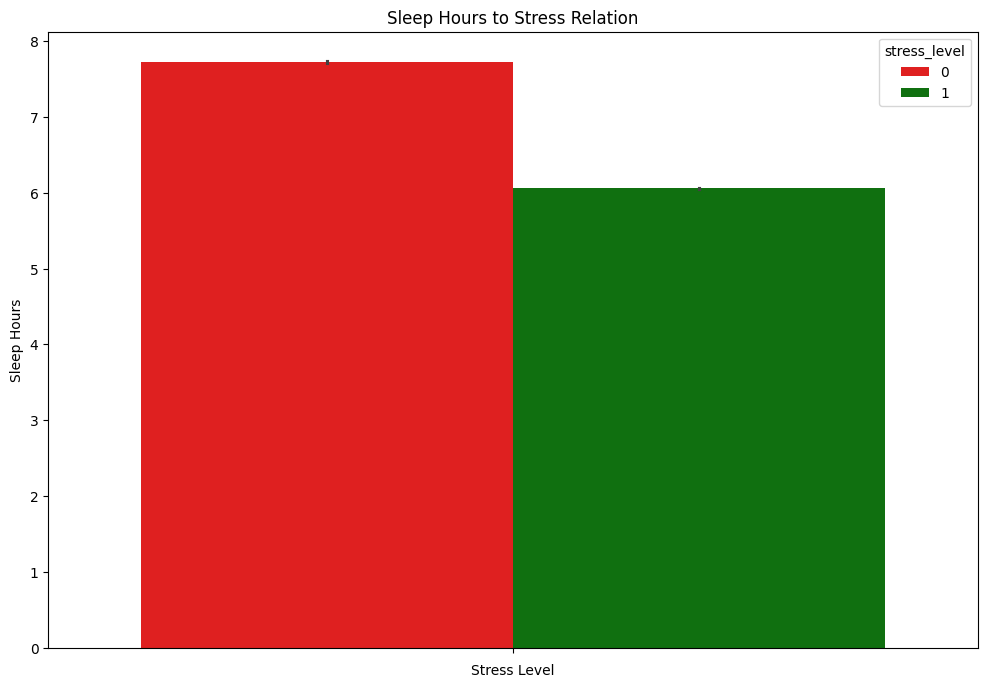

In [ ]:
#sleep hours to stress relation


plt.figure(figsize=(12,8))
sns.barplot(hue='stress_level',y='sleep_hours',data=df,palette=["red","green","yellow",'grey'])
plt.xlabel('Stress Level')
plt.ylabel('Sleep Hours')
plt.title('Sleep Hours to Stress Relation')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

x=df.drop(['stress_level'],axis=1)
y=df['stress_level']



x_train,x_test,y_train,y_test=train_test_split(x,
                                               y,
                                               test_size=0.2,
                                               random_state=42,
                                               stratify=y)
print("Train size ", x_train.shape)

Train size  (80000, 6)


In [ ]:
y_train.value_counts()


,count
stress_level,
0,44678
1,35322


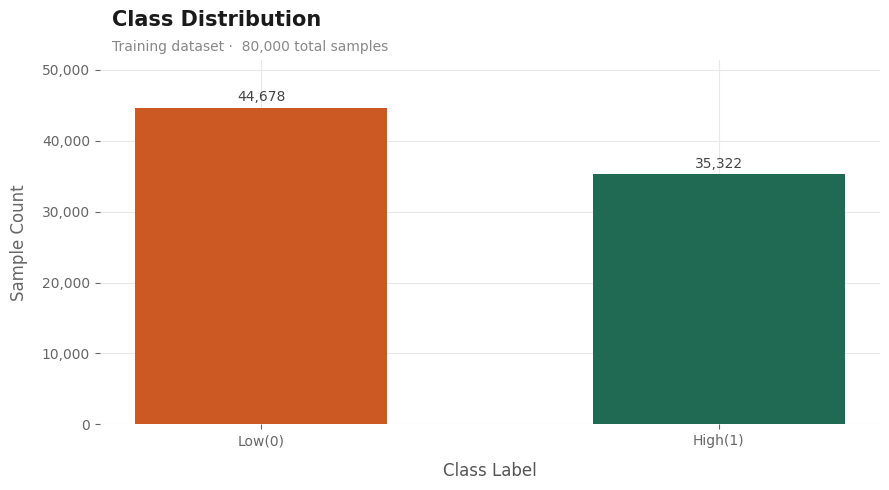

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np

# ── Style ────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'axes.spines.left': False,
    'axes.spines.bottom': False,
    'axes.grid':        True,
    'grid.color':       '#e8e8e8',
    'grid.linewidth':   0.8,
    'figure.facecolor': '#ffffff',
    'axes.facecolor':   '#ffffff',
})

# ── Figure ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

classes      = np.unique(y_train)
class_counts = [np.sum(y_train == c) for c in classes]
palette      = sns.color_palette(['#cc5823','#206953'], len(classes))

bars = ax.bar(
    classes, class_counts,
    color=palette,
    width=0.55,
    zorder=3,
)

# ── Bar labels ─────────────────────────────────────────────────────────────────
for bar, count in zip(bars, class_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(class_counts) * 0.01,
        f'{count:,}',
        ha='center', va='bottom',
        fontsize=10, color='#444444', fontweight='500',
    )

# ── Axes ───────────────────────────────────────────────────────────────────────
ax.set_xlabel('Class Label',  fontsize=12, color='#555555', labelpad=10)
ax.set_ylabel('Sample Count', fontsize=12, color='#666666', labelpad=10)
ax.tick_params(colors='#666666', labelsize=10)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_ylim(0, max(class_counts) * 1.15)
ax.set_xticks(classes)
ax.set_xticklabels(['Low(0)','High(1)'])

# ── Title block ────────────────────────────────────────────────────────────────
fig.text(0.13, 0.97, 'Class Distribution',
         fontsize=15, fontweight='bold', color='#1a1a1a', va='top')
fig.text(0.13, 0.91, f'Training dataset ·  {len(y_train):,} total samples',
         fontsize=10, color='#888888', va='top')

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

In [ ]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline


In [ ]:
from collections import Counter
print(Counter(y_train))


Counter({0: 44678, 1: 35322})


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import shap

In [ ]:
lr=LogisticRegression(penalty='l1',solver='liblinear')
svm=SVC(probability=True,kernel='rbf')

#Logistic Regression

CV Mean Accuracy: 0.8453375
CV Mean AUC: 0.9297906084610688

Test Accuracy: 0.8463
Test AUC: 0.9293371388987055

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.86     11169
           1       0.83      0.82      0.83      8831

    accuracy                           0.85     20000
   macro avg       0.84      0.84      0.84     20000
weighted avg       0.85      0.85      0.85     20000



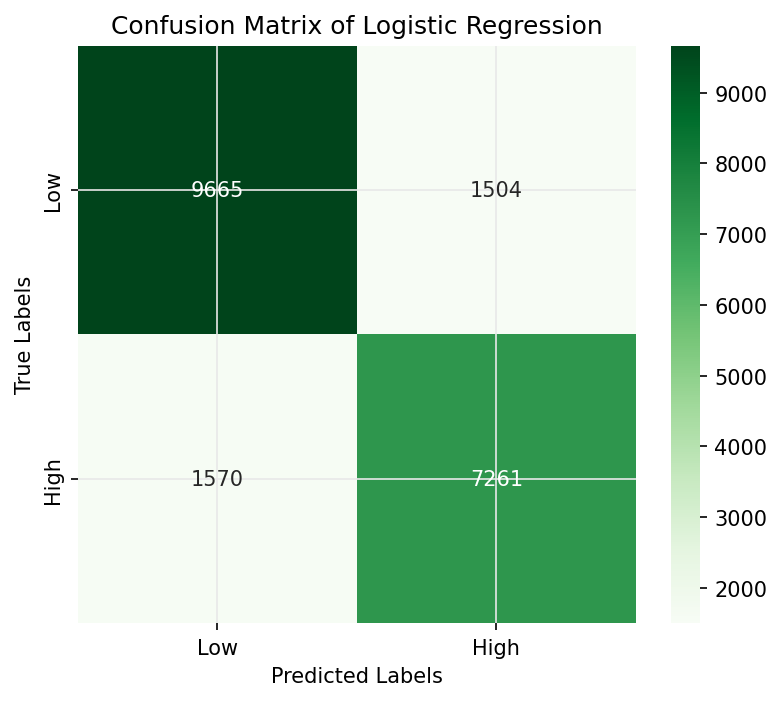

In [ ]:


pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', lr)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_acc_scores = cross_val_score(pipe, x_train, y_train, cv=cv, scoring='accuracy')
lr_auc_scores = cross_val_score(pipe, x_train, y_train, cv=cv, scoring='roc_auc')

print("CV Mean Accuracy:", lr_acc_scores.mean())
print("CV Mean AUC:", lr_auc_scores.mean())

pipe.fit(x_train, y_train)

y_pred = pipe.predict(x_test)
y_prob = pipe.predict_proba(x_test)[:, 1]

print("\nTest Accuracy:", accuracy_score(y_test, y_pred))
print("Test AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6,5),dpi=150)
cm_lr = confusion_matrix(y_test, y_pred)

sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Greens",
            xticklabels=['Low','High'],
            yticklabels=['Low','High'])

plt.title("Confusion Matrix of Logistic Regression")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


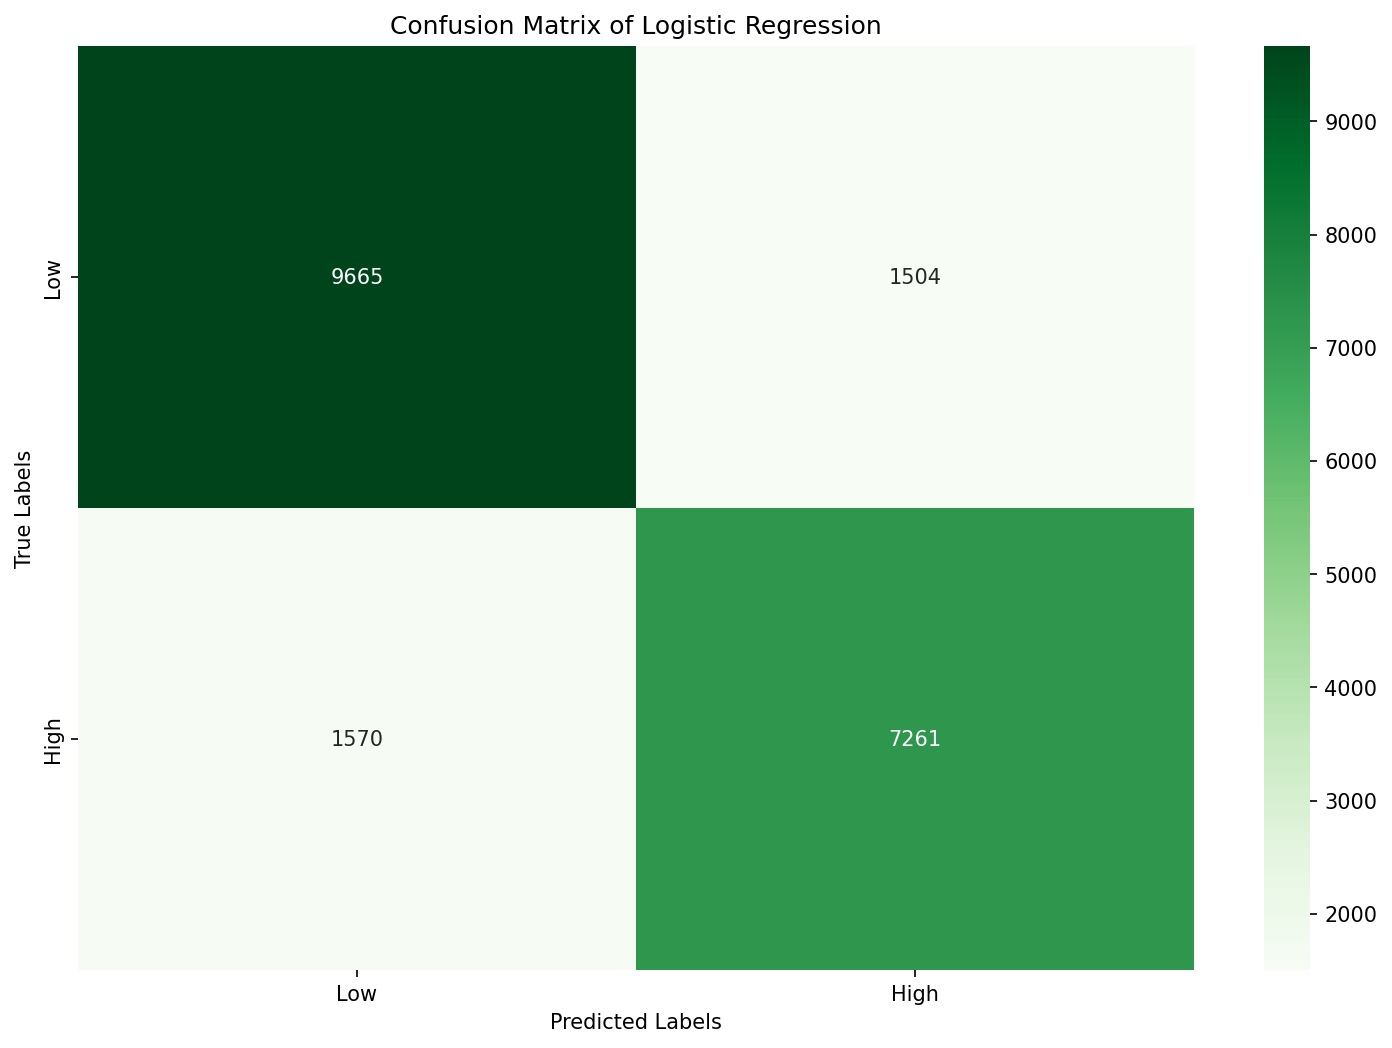

In [ ]:
plt.figure(figsize=(12,8),dpi=150)
cm_lr = confusion_matrix(y_test, y_pred)

sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Greens",
            xticklabels=['Low','High'],
            yticklabels=['Low','High'])
plt.grid(False)
plt.title("Confusion Matrix of Logistic Regression")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


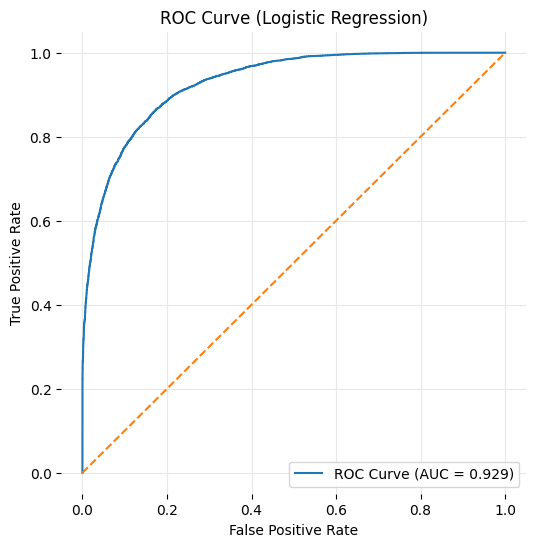

In [ ]:


fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Logistic Regression)')
plt.legend()
plt.show()


ExAI for Logistic Regression

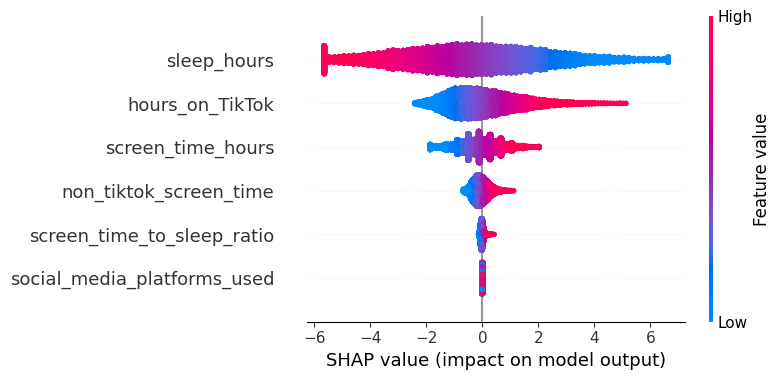

In [ ]:

bg_data=x_train.sample(100,random_state=42)

bg_scaled=pipe.named_steps['scaler'].transform(bg_data)
x_test_scaled=pipe.named_steps['scaler'].transform(x_test)

lr_explainer=shap.LinearExplainer(pipe.named_steps['lr'],bg_scaled)

shap_values=lr_explainer.shap_values(x_test_scaled)

shap.summary_plot(shap_values,x_test_scaled,feature_names=x_train.columns)


### Naive Bayes

CV mean Accuracy Score:  0.8132249999999999
CV mean AUC Score:  0.9013827907044483
Test Accuracy:  0.8199
Test AUC:  0.9049794056151687
              precision    recall  f1-score   support

           0       0.82      0.86      0.84     11169
           1       0.81      0.77      0.79      8831

    accuracy                           0.82     20000
   macro avg       0.82      0.81      0.82     20000
weighted avg       0.82      0.82      0.82     20000



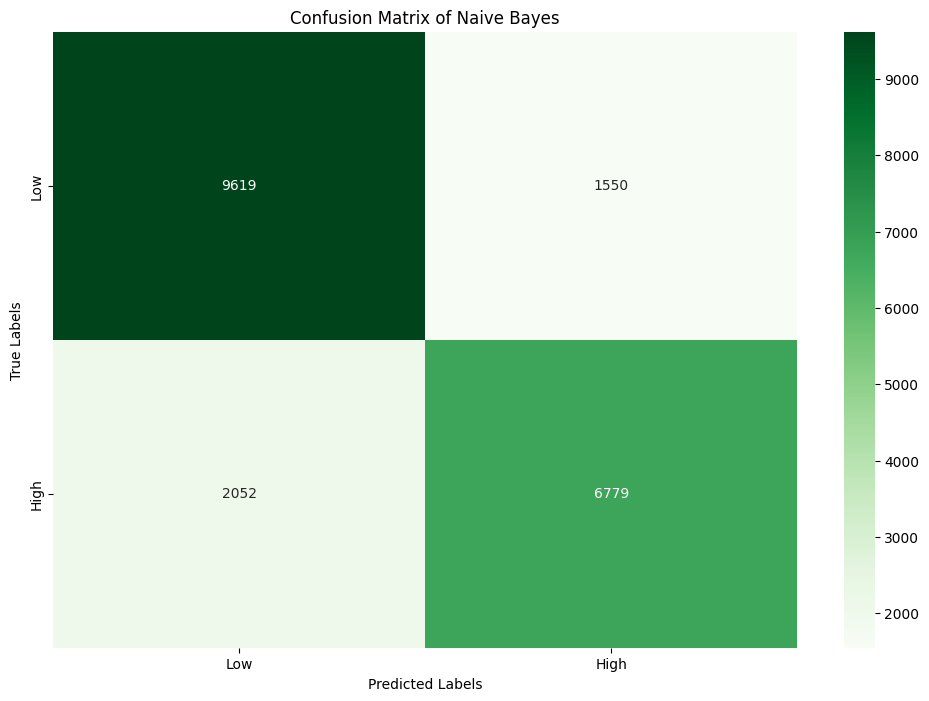

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

nb_pipe=Pipeline(
    [('scaler',StandardScaler()),
     ('nb',nb)]
)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

nb_acc_scores=cross_val_score(nb_pipe,x_train,y_train,cv=cv,scoring='accuracy')
nb_auc_scores=cross_val_score(nb_pipe,x_train,y_train,cv=cv,scoring='roc_auc')

print("CV mean Accuracy Score: ",nb_acc_scores.mean())
print("CV mean AUC Score: ",nb_auc_scores.mean())

nb_pipe.fit(x_train,y_train)

nb_y_pred=nb_pipe.predict(x_test)
nb_y_prob=nb_pipe.predict_proba(x_test)[:,1]

print("Test Accuracy: ",accuracy_score(y_test,nb_y_pred))
print("Test AUC: ",roc_auc_score(y_test,nb_y_prob))

clf_nb=classification_report(y_test,nb_y_pred)
print(clf_nb)
plt.figure(figsize=(12,8))
cm_nb=confusion_matrix(y_test,nb_y_pred)
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Greens",
            xticklabels=['Low','High'], yticklabels=['Low','High'])
plt.title("Confusion Matrix of Naive Bayes")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

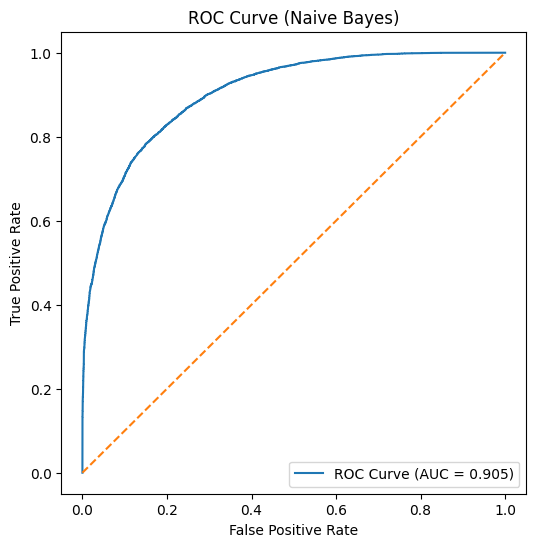

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, nb_y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Naive Bayes)')
plt.legend()
plt.legend()

ExAI for NB

  0%|          | 0/20000 [00:00<?, ?it/s]

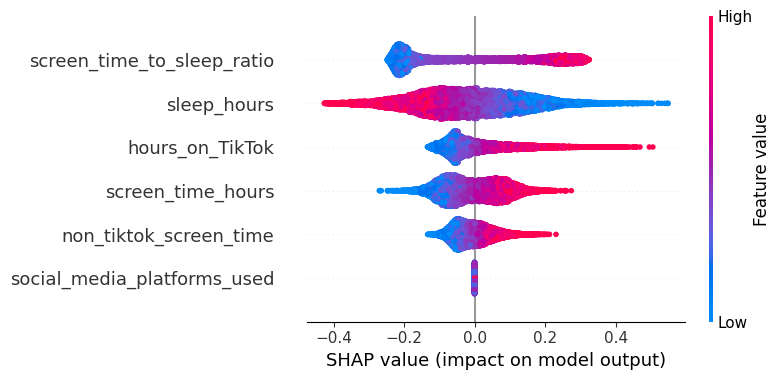

In [ ]:
bg_data=x_train.sample(100,random_state=42)
bg_scaled=nb_pipe.named_steps['scaler'].transform(bg_data)
x_test_scaled=nb_pipe.named_steps['scaler'].transform(x_test)

nb_explainer=shap.KernelExplainer(
    lambda x: nb_pipe.named_steps['nb'].predict_proba(x)[:, 1],
    bg_scaled
)

shap_values=nb_explainer.shap_values(x_test_scaled)

shap.summary_plot(shap_values,
                  x_test_scaled,
                  feature_names=x_train.columns)


### SVM

CV Accuracy Score:  0.845075
CV AUC Score:  0.912465056219595
Test Accuracy:  0.8471
Test AUC:  0.9096010887342173
              precision    recall  f1-score   support

           0       0.86      0.87      0.86     11169
           1       0.83      0.82      0.83      8831

    accuracy                           0.85     20000
   macro avg       0.85      0.84      0.84     20000
weighted avg       0.85      0.85      0.85     20000



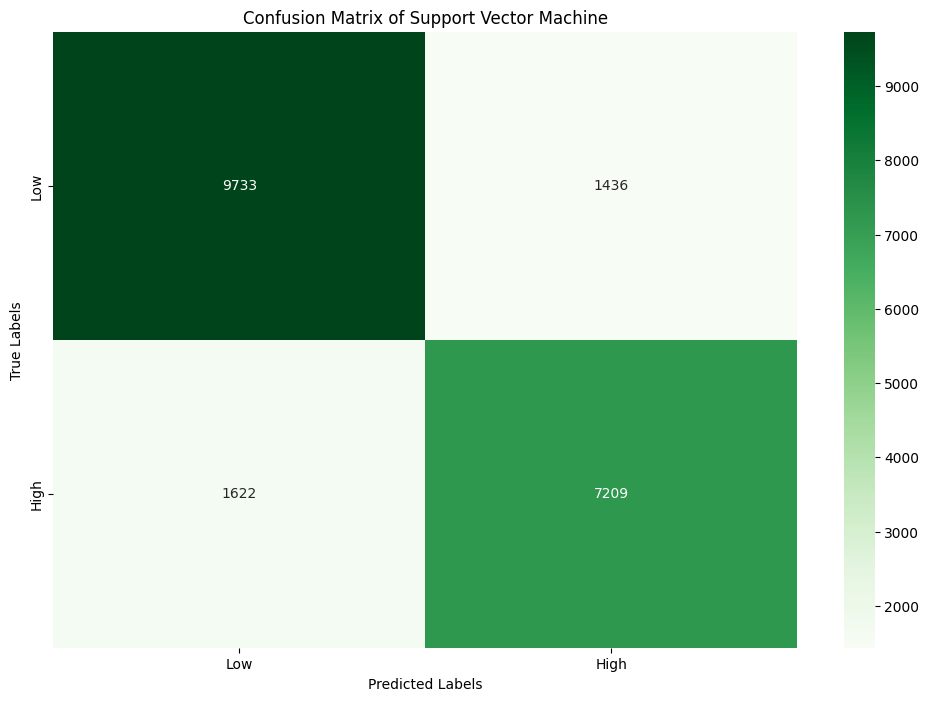

In [ ]:
svm_pipe=Pipeline(
    [('scaler',StandardScaler()),
     ('svm',svm)]
)
cv=StratifiedKFold(n_splits=2,shuffle=True,random_state=42)

svm_acc_scores=cross_val_score(svm_pipe,
                               x_train,
                               y_train,
                               cv=cv,scoring='accuracy')
svm_auc_scores=cross_val_score(svm_pipe,
                               x_train,
                               y_train,
                               cv=cv,scoring='roc_auc')

print("CV Accuracy Score: ",svm_acc_scores.mean())
print("CV AUC Score: ",svm_auc_scores.mean())

svm_pipe.fit(x_train,y_train)

svm_y_pred=svm_pipe.predict(x_test)
svm_y_prob=svm_pipe.predict_proba(x_test)[:,1]

print("Test Accuracy: ",accuracy_score(y_test,svm_y_pred))
print("Test AUC: ",roc_auc_score(y_test,svm_y_prob))

clf_svm=classification_report(y_test,svm_y_pred)
print(clf_svm)
plt.figure(figsize=(12,8))
cm_svm=confusion_matrix(y_test,svm_y_pred)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens",
            xticklabels=['Low','High'], yticklabels=['Low','High'])
plt.grid(False)
plt.title("Confusion Matrix of Support Vector Machine")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

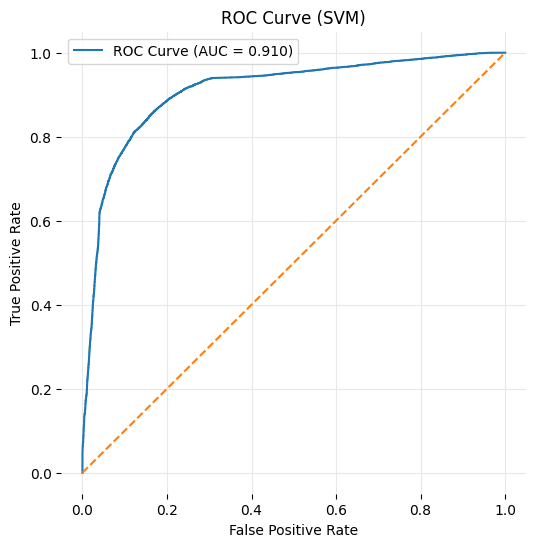

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, svm_y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (SVM)')
plt.legend()
plt.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

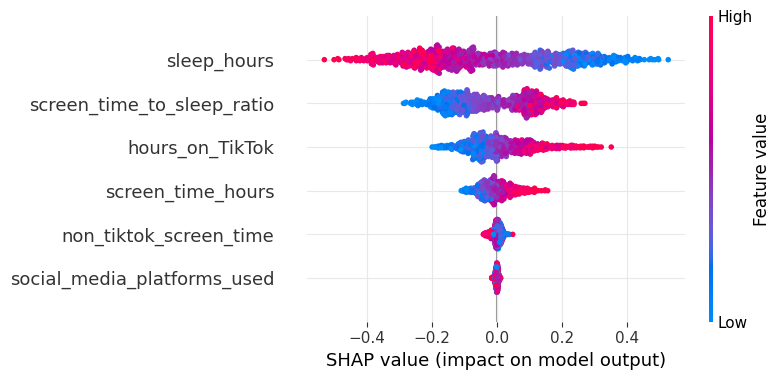

In [ ]:
bg_data=x_train.sample(100,random_state=42)
bg_scaled=svm_pipe.named_steps['scaler'].transform(bg_data)
x_test_scaled=svm_pipe.named_steps['scaler'].transform(x_test)
svm_explainer=shap.KernelExplainer(
    lambda x: svm_pipe.named_steps['svm'].predict_proba(x)[:, 1],
    bg_scaled
)

shap_values=svm_explainer.shap_values(x_test_scaled[:1000])
shap.summary_plot(shap_values,x_test_scaled[:1000],feature_names=x_train.columns)

### MLP

CV Mean Accuracy: 0.8458625
CV Mean AUC: 0.9289950482771829

Test Accuracy: 0.8463
Test AUC: 0.9289698192516637
              precision    recall  f1-score   support

           0       0.86      0.86      0.86     11169
           1       0.83      0.83      0.83      8831

    accuracy                           0.85     20000
   macro avg       0.84      0.84      0.84     20000
weighted avg       0.85      0.85      0.85     20000



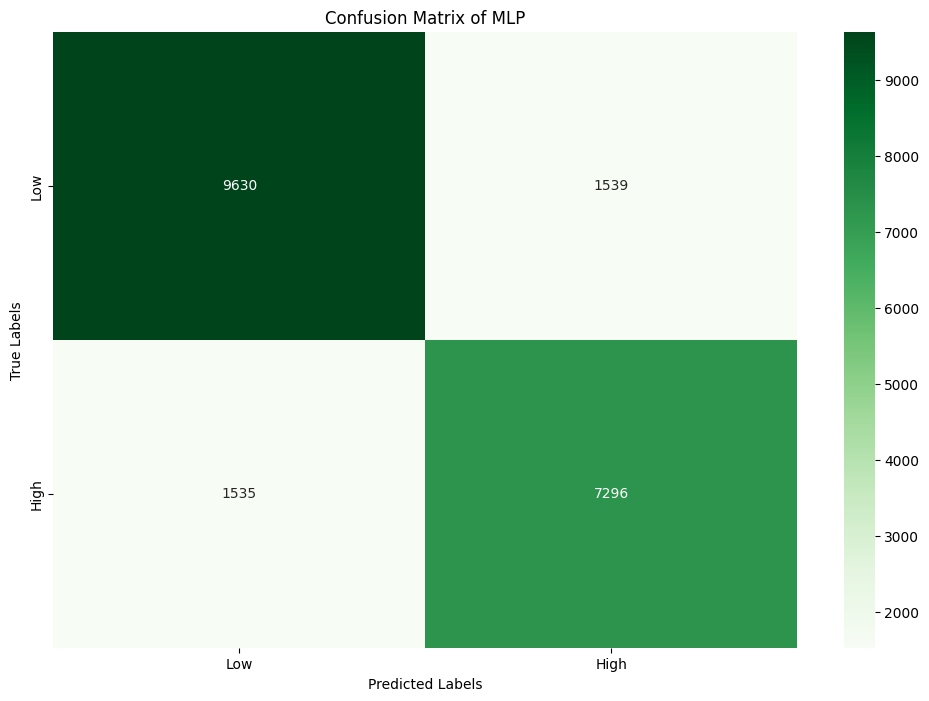

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=(64,32,16, 8),
        activation='relu',
        solver='adam',
        alpha=0.002,
        learning_rate_init=0.00001,
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=42
    ))
])

mlp_pipe=Pipeline([
    ('scaler',StandardScaler()),
    ('mlp',mlp)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mlp_acc_scores = cross_val_score(mlp,
                                 x_train,
                                 y_train,
                                 cv=cv,
                                 scoring='accuracy')
mlp_auc_scores = cross_val_score(mlp,
                                 x_train,
                                 y_train,
                                 cv=cv,
                                 scoring='roc_auc')

print("CV Mean Accuracy:", mlp_acc_scores.mean())
print("CV Mean AUC:", mlp_auc_scores.mean())

mlp_pipe = mlp.fit(x_train, y_train)

mlp_y_pred = mlp_pipe.predict(x_test)
mlp_y_prob = mlp_pipe.predict_proba(x_test)[:, 1]

print("\nTest Accuracy:", accuracy_score(y_test, mlp_y_pred))
print("Test AUC:", roc_auc_score(y_test, mlp_y_prob))

clf_mlp=classification_report(y_test,mlp_y_pred)
print(clf_mlp)

plt.figure(figsize=(12,8))
cm_mlp=confusion_matrix(y_test,mlp_y_pred)
sns.heatmap(cm_mlp, annot=True, fmt="d", cmap="Greens",
            xticklabels=['Low','High'], yticklabels=['Low','High'])
plt.title("Confusion Matrix of MLP")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

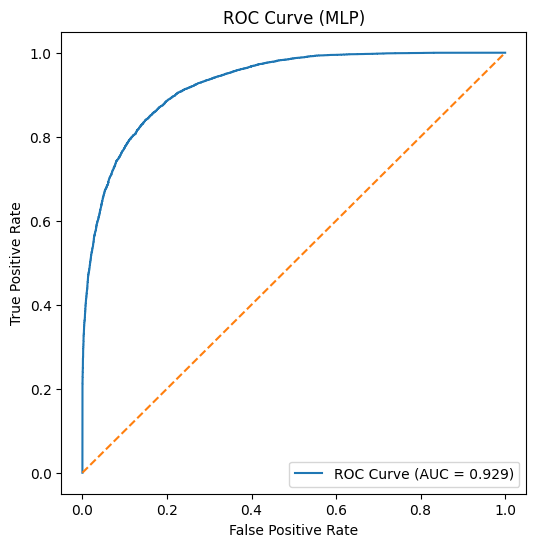

In [ ]:
fpr , tpr , thresholds = roc_curve(y_test,mlp_y_prob)
roc_auc = auc(fpr,tpr)

plt.figure(figsize=(6,6))

plt.plot(fpr,tpr,label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0,1],[0,1],linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (MLP)')
plt.legend()
plt.show()

EXAI for MLP

  0%|          | 0/20000 [00:00<?, ?it/s]

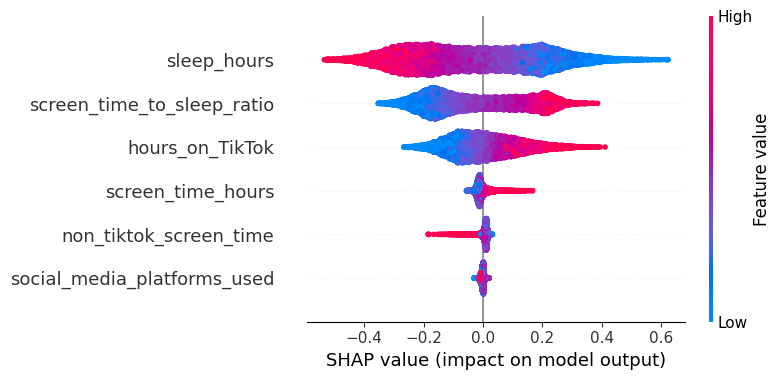

In [ ]:
bg_scaled=mlp_pipe.named_steps['scaler'].transform(x_train.sample(100,random_state=42))
x_test_scaled=mlp_pipe.named_steps['scaler'].transform(x_test)
mlp_explainer = shap.KernelExplainer(
    lambda x: mlp_pipe.named_steps['mlp'].predict_proba(x)[:, 1],
    bg_scaled
)

shap_values = mlp_explainer.shap_values(x_test_scaled)

shap.summary_plot(
    shap_values,
    x_test_scaled,
    feature_names=x_train.columns
)